In [3]:
print("My first AI/ML project!")

My first AI/ML project!


In [4]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

print("\nFlower class counts:")
print(df["target"].value_counts())

Dataset shape: (150, 5)

Column names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='object')

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Flower class counts:
target
0    50
1    50
2    50
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import train_test_split

X = df.drop("target", axis=1)

y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training samples: 120
Testing samples: 30
Training features: (120, 4)
Testing features: (30, 4)


In [7]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [8]:
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.values)

print("\nPredicted values:")
print(y_pred)

Actual values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [9]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 93.33333333333333 %


In [15]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



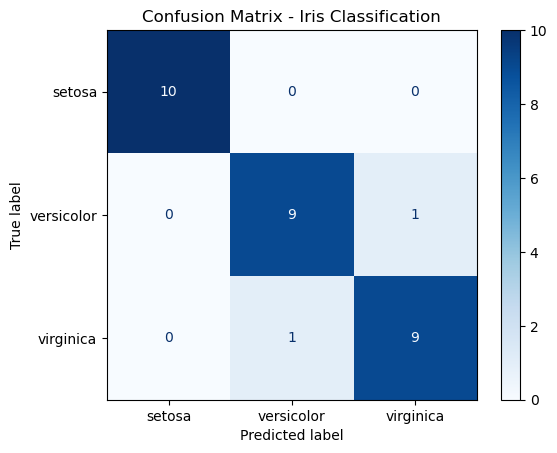

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Iris Classification")

plt.savefig("images/confusion_matrix.png", dpi=300, bbox_inches="tight")

plt.show()

In [11]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



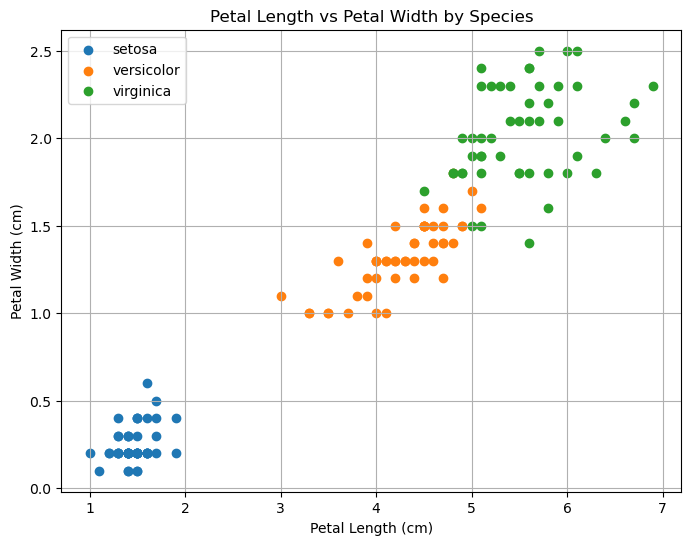

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for species in range(3):
    species_data = df[df["target"] == species]

    plt.scatter(
        species_data["petal length (cm)"],
        species_data["petal width (cm)"],
        label=iris.target_names[species]
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Petal Length vs Petal Width by Species")
plt.legend()
plt.grid(True)

plt.savefig("images/petal_scatter.png",
            dpi=300, bbox_inches="tight")

plt.show()

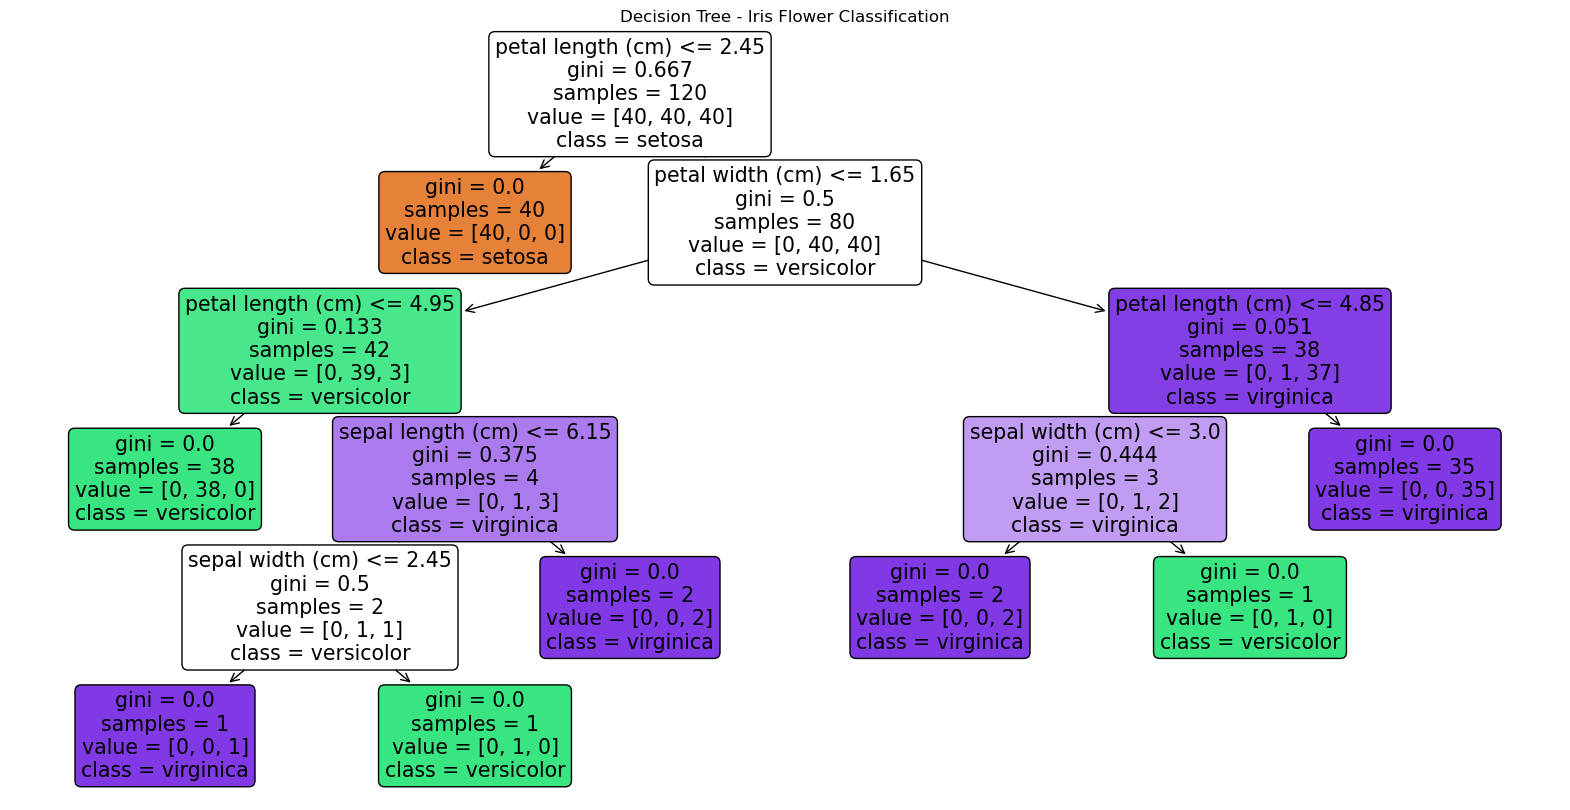

In [19]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Iris Flower Classification")
plt.savefig("images/decision_tree.png",
            dpi=300, bbox_inches="tight")

plt.show()

Feature Importance:
petal length (cm)    0.558568
petal width (cm)     0.406015
sepal width (cm)     0.029167
sepal length (cm)    0.006250
dtype: float64


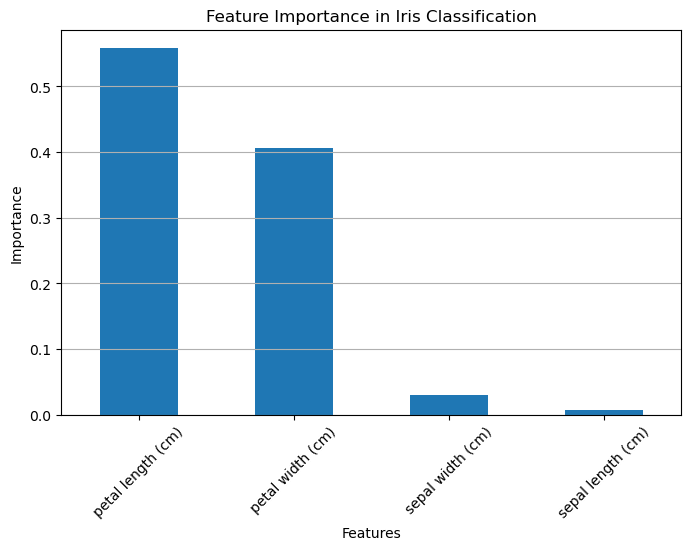

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(importance)

importance.plot(kind="bar", figsize=(8, 5))

plt.title("Feature Importance in Iris Classification")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.savefig("images/feature_importance.png",
            dpi=300, bbox_inches="tight")

plt.show()

### Classification Report Analysis

The Decision Tree achieved an overall accuracy of 93.33%.

- Setosa: 100% precision and recall.
- Versicolor: 90% precision and recall.
- Virginica: 90% precision and recall.

The model classified all Setosa flowers correctly but made
two incorrect predictions involving the other species.

The macro and weighted averages were both 0.93.